In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Persona batch 2 — which half of "poor student" works, brand stereotypes, and user vs role voice

Follow-up to [persona_vs_contracts.ipynb](persona_vs_contracts.ipynb). All runs are qwen-32B and
qwen-72B, no contract, `data/laptops_persona/` (PMI off), compared with the `shopping` runs
`none`, `ram=4GB`, `ram=8GB`, `ram=16GB` in `laptops_robustness`.

| frame | prompt prefix | question |
|---|---|---|
| `student` | I am a student and I do not have much money. I am looking to buy a laptop. | batch 1 |
| `student_only` | I am a student. … | which half of `student` carries it: identity … |
| `no_money` | I do not have much money. … | … or money |
| `editor` | I am a professional video editor. … | batch 1 (qwen-72B landed now) |
| `windows` | My company only supports Windows. … | brand stereotype, away from Apple, no price in it |
| `designer` | I am a graphic designer. … | brand stereotype, toward Apple |
| `role_none` | Act as a person who is looking to buy a laptop. | the "Act as" wording alone |
| `role_student` | Act as a student who does not have much money and is looking to buy a laptop. | role voice × student |

Only feature weights, utility ranks and the position-corrected D are used (immune to the PMI
constant); γ is not.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.bt import FeatureBT

FIGDIR = "figs/persona"
os.makedirs(FIGDIR, exist_ok=True)
SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": True,
    "grid.color": "#e8e7e3", "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
SCREEN, RAM = ["13-inch", "14-inch", "16-inch"], ["4GB", "8GB", "16GB"]
LEVELS = {"brand": BRANDS, "screen": SCREEN, "ram": RAM}
LAPTOPS = [(b, s, r) for b in BRANDS for s in SCREEN for r in RAM]
MODELS = [("qwen", "32"), ("qwen", "72")]
CONTRACTS = ["none", "ram=4GB", "ram=8GB", "ram=16GB"]
PERSONAS = ["student", "student_only", "no_money", "editor", "windows", "designer", "role_none", "role_student"]
ORDER = ["none"] + PERSONAS + CONTRACTS[1:]
RUN_COLOR = {"none": "#8d8b85", "student": "#eb6834", "student_only": "#f2a65a", "no_money": "#b8431a",
             "editor": "#e87ba4", "windows": "#1baf7a", "designer": "#9c27b0",
             "role_none": "#555250", "role_student": "#2a78d6",
             "ram=4GB": "#2a78d6", "ram=8GB": "#1baf7a", "ram=16GB": "#4a3aa7"}


def load():
    """Complete runs only, one per (model, run) - asserted. A persona run is keyed by its frame
    name, a shopping run by its constraints_id."""
    R = {}
    for base in ["data/laptops_robustness", "data/laptops_persona"]:
        for r in sorted(os.listdir(base)):
            cf, sc = f"{base}/{r}/config.json", f"{base}/{r}/scores.csv"
            if not (os.path.isfile(cf) and os.path.isfile(sc)):
                continue
            c = json.load(open(cf))
            m = (c["model_family"], str(c["model_size"]))
            fr, cid = c["frame"]["name"], c["constraints_id"]
            if m not in MODELS or cid not in CONTRACTS:
                continue
            if fr == "shopping":
                run = cid
            elif cid == "none" and fr in PERSONAS:
                run = fr
            else:
                continue
            d = pd.read_csv(sc)
            if len(d) != 9900:
                continue
            assert (m, run) not in R, f"two complete runs for {m} {run}"
            R[(m, run)] = d
    return R


def D(d, f, u, v):
    """Position-corrected margin of level u over v on feature f, other features tied: one value
    per (pair, template)."""
    o = [x for x in ("brand", "screen", "ram") if x != f]
    t = d[(d[f"a_{o[0]}"] == d[f"b_{o[0]}"]) & (d[f"a_{o[1]}"] == d[f"b_{o[1]}"]) & d[f"a_{f}"].isin([u, v])
          & d[f"b_{f}"].isin([u, v]) & (d[f"a_{f}"] != d[f"b_{f}"])]
    val = np.where(t[f"a_{f}"] == u, t.score_a - t.score_b, t.score_b - t.score_a)
    return pd.Series(val).groupby((t[f"a_{o[0]}"] + t[f"a_{o[1]}"] + t.template_idx.astype(str)).values).mean()


def util(k):
    f = FITS[k]
    return pd.Series({l: f.utility(dict(brand=l[0], screen=l[1], ram=l[2])) for l in LAPTOPS})


def name(m):
    return f"{m[0]}-{m[1]}B"


RUNS = load()
FITS = {k: FeatureBT(r2_warn=None).fit(d) for k, d in RUNS.items()}
for m in MODELS:
    print(f"{name(m)}:", [r for r in ORDER if (m, r) in RUNS])
pd.set_option("display.width", 250)

qwen-32B: ['none', 'student', 'student_only', 'no_money', 'editor', 'windows', 'designer', 'role_none', 'role_student', 'ram=4GB', 'ram=8GB', 'ram=16GB']
qwen-72B: ['none', 'student', 'student_only', 'no_money', 'editor', 'windows', 'designer', 'role_none', 'role_student', 'ram=4GB', 'ram=8GB', 'ram=16GB']


## F0 — weight change vs `none`, every frame (heatmap)

One row per run, one column per feature level. Cell = the centred weight (log-odds) minus the
no-persona / no-contract weight of the same model. Blue = the level lost weight, red = it gained;
grey = unchanged. Same colour scale in both panels. The three explicit RAM contracts sit at the
bottom for scale. Numbers printed below.

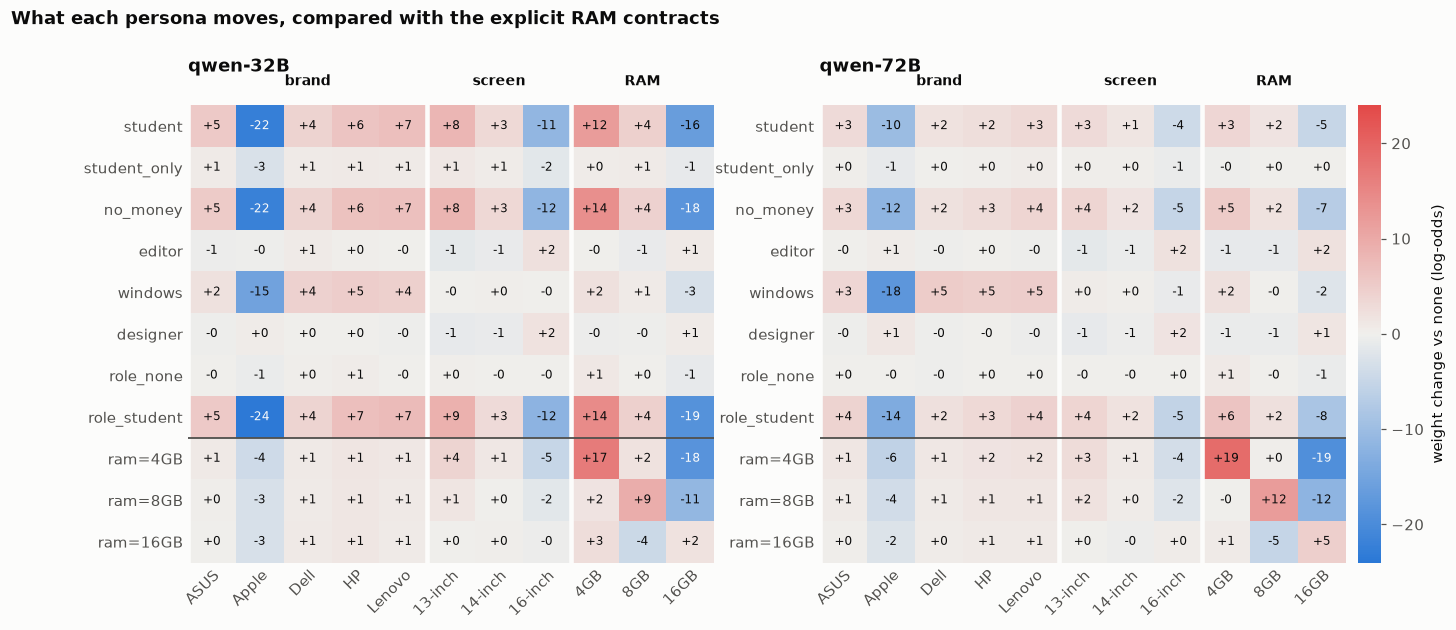

                       ASUS  Apple  Dell   HP  Lenovo  13-inch  14-inch  16-inch   4GB   8GB  16GB
model    run                                                                                      
qwen-32B student        5.3  -22.4   4.1  6.2     6.8      8.1      3.2    -11.3  12.0   4.3 -16.3
         student_only   0.6   -2.7   0.6  0.8     0.7      1.1      0.5     -1.6   0.4   0.6  -1.0
         no_money       5.1  -22.0   3.8  6.4     6.6      8.3      3.2    -11.6  13.8   4.2 -18.0
         editor        -0.5   -0.3   0.7  0.3    -0.2     -1.4     -0.8      2.2  -0.0  -0.9   0.9
         windows        1.9  -15.4   4.3  4.8     4.4     -0.1      0.2     -0.1   2.2   0.7  -3.0
         designer      -0.2    0.4   0.1  0.0    -0.3     -1.0     -0.8      1.8  -0.5  -0.3   0.7
         role_none     -0.0   -0.7   0.2  0.5    -0.0      0.3     -0.1     -0.2   1.0   0.1  -1.1
         role_student   5.4  -23.5   3.8  6.8     7.4      8.9      2.9    -11.8  14.3   4.5 -18.7
         r

In [3]:
rows = []
for m in MODELS:
    w0 = FITS[(m, "none")].weights_
    for run in ORDER[1:]:
        if (m, run) not in FITS:
            continue
        w = FITS[(m, run)].weights_
        rows.append({"model": name(m), "run": run, **{l: w[f][l] - w0[f][l] for f in LEVELS for l in LEVELS[f]}})
CH = pd.DataFrame(rows).set_index(["model", "run"])

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])   # blue - grey - red
LV = [l for f in LEVELS for l in LEVELS[f]]
RUNS_ROWS = ORDER[1:]


def heat(ax, M, cols, cmap, norm, fmt, row_text=None, groups=None):
    """M: DataFrame rows=runs, cols=cols. Writes the value in every cell, ink chosen by cell darkness."""
    im = ax.imshow(M[cols].values, cmap=cmap, norm=norm, aspect="auto")
    for i, run in enumerate(M.index):
        for j, c in enumerate(cols):
            v = M.loc[run, c]
            rgba = cmap(norm(v))
            dark = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2] < 0.55
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=8, color=SURFACE if dark else INK)
        if row_text is not None:
            ax.text(len(cols) - 0.4, i, row_text[run], ha="left", va="center", fontsize=8, color=INK_MUTED)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(len(M)), M.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    if groups:
        for k, lab, xc in groups:
            ax.axvline(k - 0.5, color=SURFACE, lw=3)
            ax.text(xc, -0.9, lab, ha="center", va="bottom", fontsize=9, fontweight="bold")
    # separate personas from the explicit contracts
    ncon = sum(r.startswith("ram=") for r in M.index)
    if 0 < ncon < len(M):
        ax.axhline(len(M) - ncon - 0.5, color=INK_MUTED, lw=1.2)
    return im


vmax = np.ceil(CH.abs().values.max())
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=False)
for ax, m in zip(axes, MODELS):
    M = CH.loc[name(m)].reindex(RUNS_ROWS).dropna(how="all")
    im = heat(ax, M, LV, DIV, norm, lambda v: f"{v:+.0f}", groups=[(5, "screen", 6), (8, "RAM", 9), (0, "brand", 2)])
    ax.set_title(name(m), loc="left", fontweight="bold", pad=22)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cb.set_label("weight change vs none (log-odds)")
cb.outline.set_visible(False)
fig.suptitle("What each persona moves, compared with the explicit RAM contracts", x=0.01, y=1.04, ha="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "P8_batch2_weight_change_heatmap.png"), facecolor=SURFACE)
plt.show()
print(CH.round(1).to_string())

## F0b — head to head, every frame (heatmap)

*Ceteris paribus* pairs (75 per cell), % won by the position-corrected D. RAM columns: does the
**lower** level win? Screen: does the **smaller** one win? Brand: does **Apple** beat each rival?
Dark = that side wins most pairs. The default is 0 in every RAM/screen column and ~100 in every
Apple column, so any dark RAM/screen cell or light Apple cell is the persona's doing. The rank-1
laptop under the additive utility is written at the right of each row. Numbers printed below.

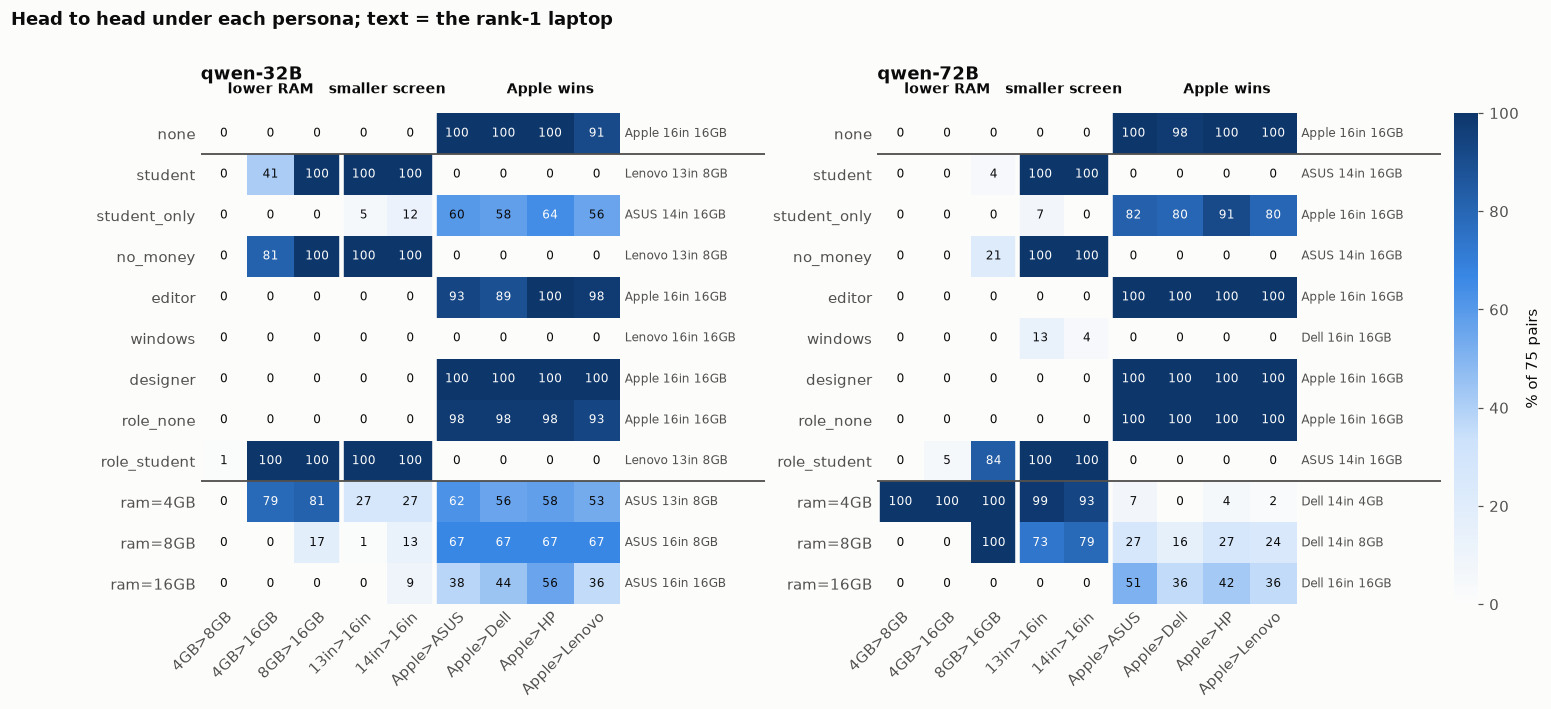

                       4GB>8GB  4GB>16GB  8GB>16GB  13in>16in  14in>16in  Apple>ASUS  Apple>Dell  Apple>HP  Apple>Lenovo                #1  Apple mean rank
model    run                                                                                                                                               
qwen-32B none              0.0       0.0       0.0        0.0        0.0       100.0       100.0     100.0          91.1   Apple 16in 16GB             19.3
         student           0.0      41.3     100.0      100.0      100.0         0.0         0.0       0.0           0.0   Lenovo 13in 8GB             40.6
         student_only      0.0       0.0       0.0        5.3       12.0        60.0        57.8      64.4          55.6    ASUS 14in 16GB             24.3
         no_money          0.0      81.3     100.0      100.0      100.0         0.0         0.0       0.0           0.0   Lenovo 13in 8GB             40.7
         editor            0.0       0.0       0.0        0.0   

In [4]:
rows = []
for m in MODELS:
    for run in ORDER:
        if (m, run) not in RUNS:
            continue
        d = RUNS[(m, run)]
        row = {"model": name(m), "run": run}
        for u, v in [("4GB", "8GB"), ("4GB", "16GB"), ("8GB", "16GB")]:
            row[f"{u}>{v}"] = 100 * (D(d, "ram", u, v) > 0).mean()
        for u, v in [("13-inch", "16-inch"), ("14-inch", "16-inch")]:
            row[f"{u[:2]}in>16in"] = 100 * (D(d, "screen", u, v) > 0).mean()
        for b in ["ASUS", "Dell", "HP", "Lenovo"]:
            row[f"Apple>{b}"] = 100 * (D(d, "brand", "Apple", b) > 0).mean()
        u = util((m, run))
        row["#1"] = " ".join(u.idxmax()).replace("-inch", "in")
        row["Apple mean rank"] = u.rank(ascending=False)[[l for l in LAPTOPS if l[0] == "Apple"]].mean()
        rows.append(row)
HH = pd.DataFrame(rows).set_index(["model", "run"])

SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#3987e5", "#0d366b"])   # one hue, light -> dark
PCT = [c for c in HH.columns if ">" in c]
norm01 = plt.Normalize(0, 100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, m in zip(axes, MODELS):
    M = HH.loc[name(m)].reindex(ORDER).dropna(how="all")
    im = heat(ax, M, PCT, SEQ, norm01, lambda v: f"{v:.0f}", row_text=M["#1"].to_dict(),
              groups=[(3, "smaller screen", 3.5), (5, "Apple wins", 7), (0, "lower RAM", 1)])
    ax.axhline(0.5, color=INK_MUTED, lw=1.2)          # default row on top
    ax.set_xlim(-0.5, len(PCT) + 2.6)
    ax.set_title(name(m), loc="left", fontweight="bold", pad=22)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cb.set_label("% of 75 pairs")
cb.outline.set_visible(False)
fig.suptitle("Head to head under each persona; text = the rank-1 laptop", x=0.01, y=1.04, ha="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "P9_batch2_head_to_head_heatmap.png"), facecolor=SURFACE)
plt.show()
print(HH.round(1).to_string())

## T3 — Spearman between the 45 laptop utilities of every pair of runs

Which run ranks the laptops like which. Read the persona rows against `none` (unchanged?) and against
`student` (same as the full persona?).

In [5]:
for m in MODELS:
    U = {run: util((m, run)) for run in ORDER if (m, run) in FITS}
    S = pd.DataFrame({a: {b: spearmanr(U[a], U[b])[0] for b in U} for a in U})
    print(name(m)); print(S.round(2).to_string()); print()

qwen-32B
              none  student  student_only  no_money  editor  windows  designer  role_none  role_student  ram=4GB  ram=8GB  ram=16GB
none          1.00    -0.04          0.96     -0.08    0.99     0.82      1.00       1.00         -0.16    -0.08     0.51      0.97
student      -0.04     1.00          0.16      1.00   -0.03     0.35     -0.05      -0.04          0.99     0.79     0.37      0.10
student_only  0.96     0.16          1.00      0.13    0.96     0.88      0.95       0.96          0.04     0.07     0.54      0.98
no_money     -0.08     1.00          0.13      1.00   -0.06     0.32     -0.08      -0.08          0.99     0.78     0.33      0.07
editor        0.99    -0.03          0.96     -0.06    1.00     0.85      1.00       1.00         -0.14    -0.10     0.52      0.98
windows       0.82     0.35          0.88      0.32    0.85     1.00      0.83       0.82          0.25     0.10     0.59      0.92
designer      1.00    -0.05          0.95     -0.08    1.00     0.8

## F1 — every feature weight, per frame

Top: the two halves of `student`. Middle: the two brand stereotypes (with `editor`). Bottom: the voice
2×2. One panel per model; the thick line is the frame under test, `none` is grey.

/tmp/ipykernel_443188/1746256149.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(x, y, "-o", color=RUN_COLOR[run], lw=2.4 if t else 1.2, ms=5 if t else 3.5, label=run,
/tmp/ipykernel_443188/1746256149.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(x, y, "-o", color=RUN_COLOR[run], lw=2.4 if t else 1.2, ms=5 if t else 3.5, label=run,
/tmp/ipykernel_443188/1746256149.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(x, y, "-o", color=RUN_COLOR[run], lw=2.4 if t else 1.2, ms=5 if t else 3.5, label=run,
/tmp/ipykernel_443188/1746256149.py:9: UserWarning: linestyle is redundantly defined 

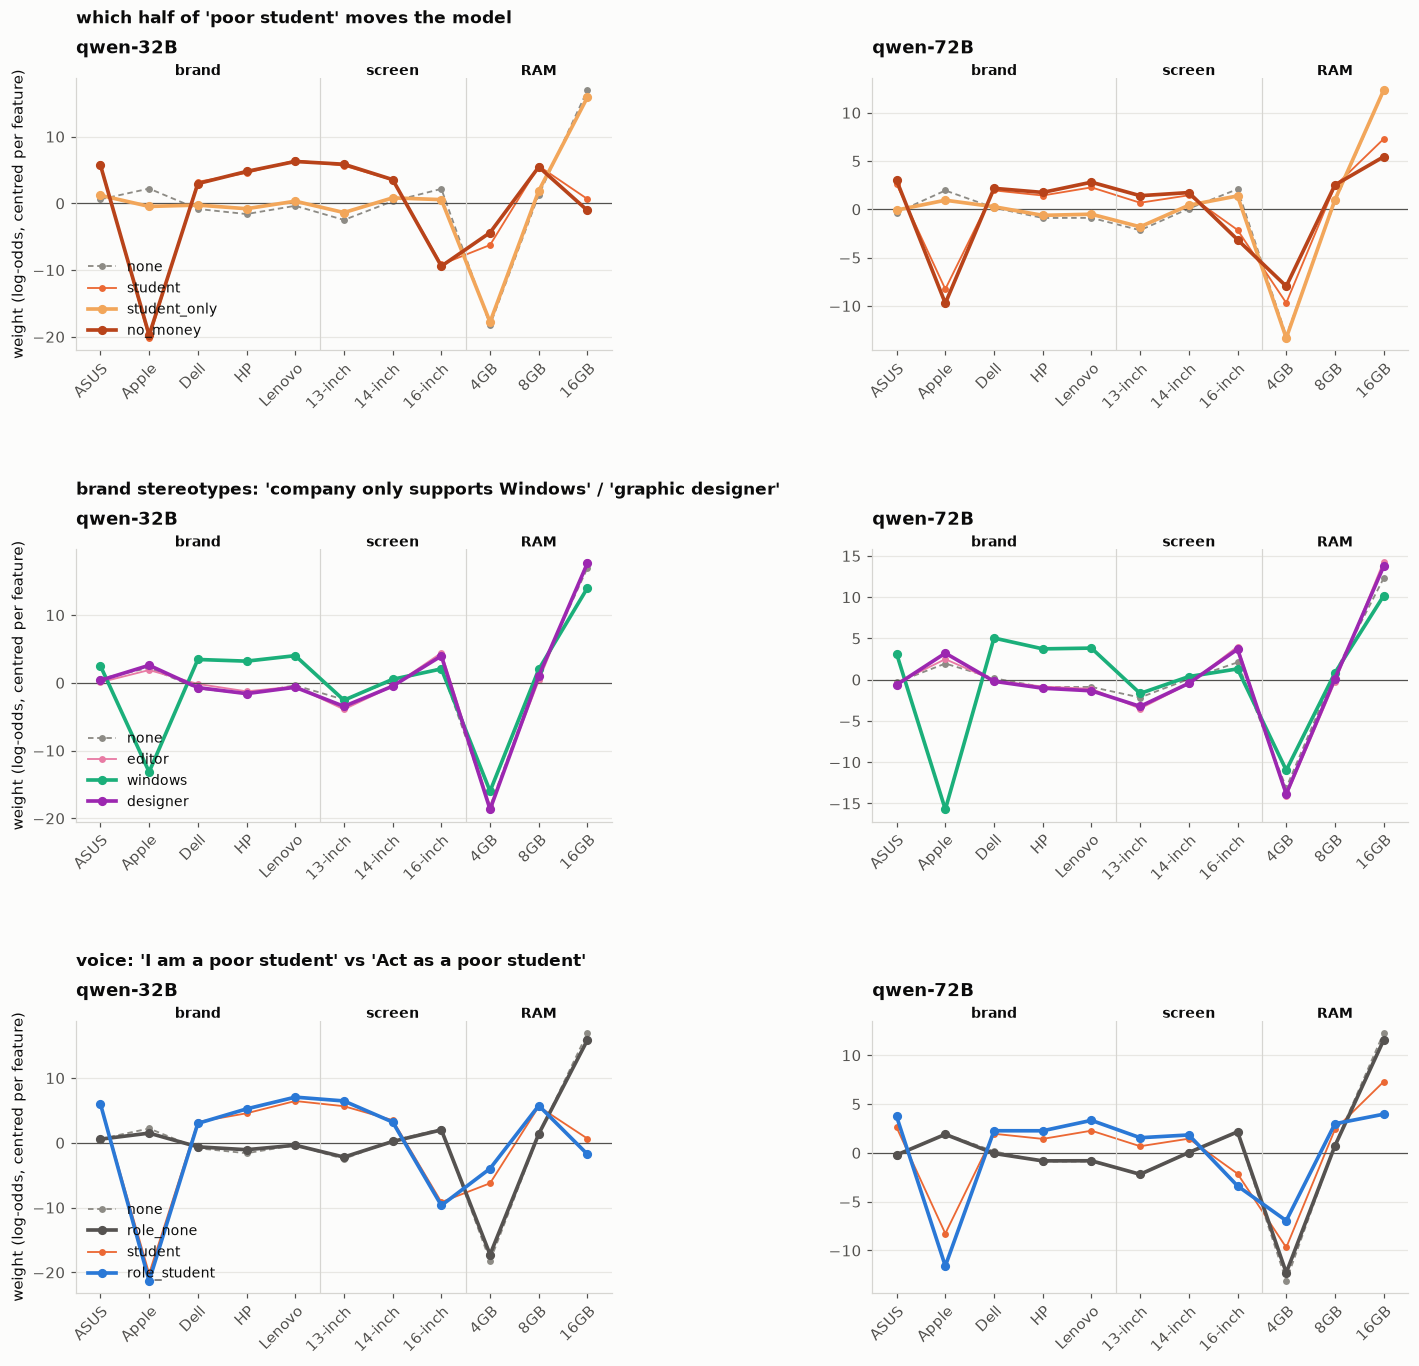

In [6]:
def weights_panel(ax, m, runs, thick):
    lv = [(f, l) for f in ("brand", "screen", "ram") for l in LEVELS[f]]
    x = np.arange(len(lv))
    for run in runs:
        if (m, run) not in FITS:
            continue
        y = [FITS[(m, run)].weights_[f][l] for f, l in lv]
        t = run in thick
        ax.plot(x, y, "-o", color=RUN_COLOR[run], lw=2.4 if t else 1.2, ms=5 if t else 3.5, label=run,
                zorder=3 if t else 2, ls="-" if run != "none" else (0, (3, 2)))
    ax.axhline(0, color=INK_MUTED, lw=0.8)
    for k in (5, 8):
        ax.axvline(k - 0.5, color="#d6d5d1", lw=0.8)
    ax.set_xticks(x, [l for _, l in lv], rotation=45, ha="right", rotation_mode="anchor")
    for xc, t in [(2, "brand"), (6, "screen"), (9, "RAM")]:
        ax.text(xc, 1.01, t, transform=ax.get_xaxis_transform(), ha="center", fontweight="bold", fontsize=9)
    ax.set_title(name(m), loc="left", fontweight="bold", pad=16)
    ax.grid(axis="x", visible=False)


PANELS = [(["none", "student", "student_only", "no_money"], ["student_only", "no_money"], "which half of 'poor student' moves the model"),
          (["none", "editor", "windows", "designer"], ["windows", "designer"], "brand stereotypes: 'company only supports Windows' / 'graphic designer'"),
          (["none", "role_none", "student", "role_student"], ["role_none", "role_student"], "voice: 'I am a poor student' vs 'Act as a poor student'")]
fig, axes = plt.subplots(len(PANELS), 2, figsize=(13, 4.2 * len(PANELS)))
for i, (runs, thick, title) in enumerate(PANELS):
    for ax, m in zip(axes[i], MODELS):
        weights_panel(ax, m, runs, thick)
    axes[i, 0].set_ylabel("weight (log-odds, centred per feature)")
    axes[i, 0].legend(frameon=False, fontsize=9, loc="lower left")
    axes[i, 0].text(0, 1.2, title, transform=axes[i, 0].transAxes, fontweight="bold", fontsize=11)
fig.tight_layout(h_pad=4)
fig.savefig(os.path.join(FIGDIR, "P6_batch2_weights.png"), facecolor=SURFACE)
plt.show()

## F2 — one number per frame: Apple's change and whether 8GB now beats 16GB

Left: Apple's weight change vs `none`. Right: % of 8GB-vs-16GB pairs the 8GB laptop wins (0 in every
default). The explicit RAM contracts are the hatched bars at the end, for scale.

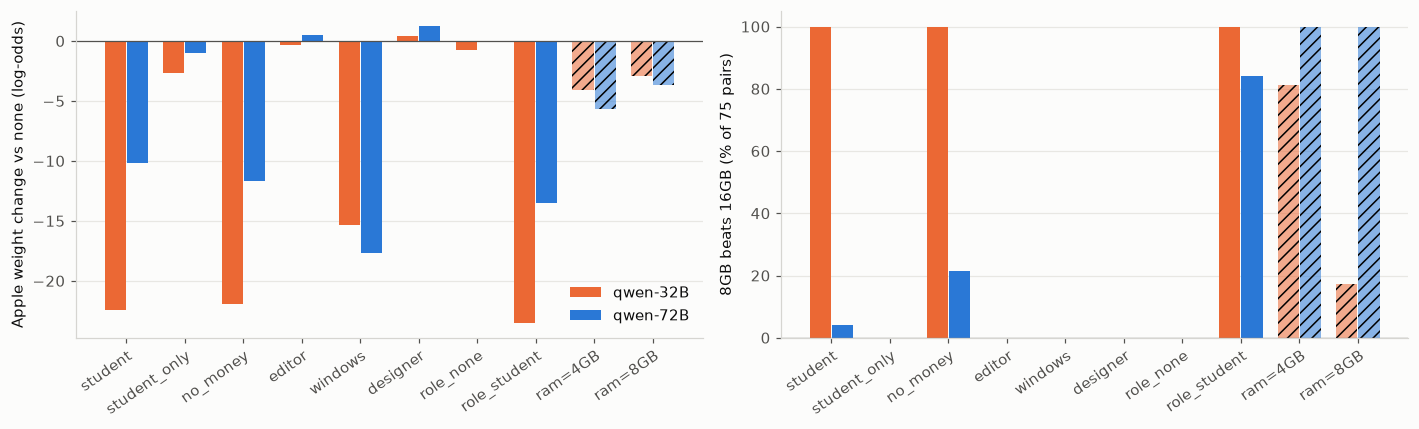

In [7]:
runs = PERSONAS + ["ram=4GB", "ram=8GB"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(runs))
for i, m in enumerate(MODELS):
    off = (i - 0.5) * 0.38
    a = [CH.loc[(name(m), r), "Apple"] if (name(m), r) in CH.index else np.nan for r in runs]
    h = [HH.loc[(name(m), r), "8GB>16GB"] if (name(m), r) in HH.index else np.nan for r in runs]
    for ax, y in zip(axes, (a, h)):
        bars = ax.bar(x + off, y, 0.36, color=["#eb6834", "#2a78d6"][i], label=name(m), zorder=2)
        for b, r in zip(bars, runs):
            if r.startswith("ram="):
                b.set_hatch("///"); b.set_alpha(0.55)
for ax, lab in zip(axes, ("Apple weight change vs none (log-odds)", "8GB beats 16GB (% of 75 pairs)")):
    ax.set_xticks(x, runs, rotation=35, ha="right", rotation_mode="anchor")
    ax.axhline(0, color=INK_MUTED, lw=0.8)
    ax.set_ylabel(lab)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "P7_batch2_apple_and_ram.png"), facecolor=SURFACE)
plt.show()